# Vail Snow and Lodging: Ridge, Random Forest and SVR Models
**Question:** How much does snowfall explain monthly lodging revenue in the Town of Vail?

**Plan (from the Model & Chart Plan):** predict monthly lodging revenue from snow + month using three models:
1. **Ridge regression** - the baseline; gives "dollars per inch of snow"
2. **Random Forest** - catches non-linear patterns (snow matters in Dec-Mar, barely in summer)
3. **SVR** - the regression version of SVM from Week 12; needs scaled features

We train on older months, test on the most recent seasons, and score with R-squared and MAE (average miss in dollars).

## 1. Load and inspect the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
df = pd.read_csv("vail_model_data.csv")
df["date"] = pd.to_datetime(df["month"])
print(df.shape, "| from", df["month"].min(), "to", df["month"].max())
df.head()

(189, 14) | from 2010-05 to 2026-09


,month,lodging_sales_tax,tax_rate,lodging_revenue,avg_snow_depth,peak_swe,new_snow,big_storm_days,avg_temp,last_month_snow,month_num,ski_season,covid,date
0,2010-05,42999,0.04,1074975.0,46.161290,20.8,24.0,1,37.916129,54.0,5,0,0,2010-05-01
1,2010-06,175523,0.04,4388075.0,1.533333,7.5,0.0,0,53.380000,24.0,6,0,0,2010-06-01
2,2010-07,285820,0.04,7145500.0,0.000000,0.0,0.0,0,57.738710,0.0,7,0,0,2010-07-01
3,2010-08,250201,0.04,6255025.0,0.000000,0.0,0.0,0,54.438710,0.0,8,0,0,2010-08-01
4,2010-09,143504,0.04,3587600.0,0.000000,0.0,0.0,0,52.023333,0.0,9,0,0,2010-09-01


The file has no missing values, but a quick check shows **8 calendar months are absent (Feb-Sep 2015)**. We leave them out rather than invent numbers, and mark the gap on the time chart.

In [2]:
full = pd.period_range(df["month"].min(), df["month"].max(), freq="M").astype(str)
print("Missing months:", [m for m in full if m not in set(df["month"])])
print("Ski-season months in the data:", sorted(df.loc[df.ski_season == 1, "month_num"].unique()))
print("COVID-flagged:", df.loc[df.covid == 1, "month"].min(), "to", df.loc[df.covid == 1, "month"].max())

Missing months: ['2015-02', '2015-03', '2015-04', '2015-05', '2015-06', '2015-07', '2015-08', '2015-09']
Ski-season months in the data: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(11), np.int64(12)]
COVID-flagged: 2020-03 to 2021-05


## 2. Build features
Features = **snow + month**, as planned. We add a COVID flag (the 2020-21 drop is not a snow effect) and a simple time trend (revenue grew a lot from 2010 to 2022 because of prices and demand, not snow).
- Snow: new snow, snow depth, peak snow water equivalent (SWE), big storm days, last month's snow
- Month: one-hot dummies (so a straight-line model can learn that July differs from January)
- `avg_temp` is left out because it mostly repeats the month pattern, and `tax_rate`/`lodging_sales_tax` are left out because they are used to compute the target.

In [3]:
snow_cols = ["new_snow", "avg_snow_depth", "peak_swe", "big_storm_days", "last_month_snow"]
df["year_index"] = (df["date"].dt.year - 2010) + (df["date"].dt.month - 1) / 12
months = pd.get_dummies(df["month_num"], prefix="m", dtype=int)
X = pd.concat([df[snow_cols], months, df[["covid", "year_index"]]], axis=1)
y = df["lodging_revenue"]
print(X.shape)

(189, 19)


## 3. Train / test split by time
Train on older months, test on the most recent seasons so the model predicts **forward in time**. Test = May 2024 onward (the last two full seasons plus the current one).

In [4]:
test_mask = df["date"] >= "2024-05-01"
X_train, X_test = X[~test_mask], X[test_mask]
y_train, y_test = y[~test_mask], y[test_mask]
print("Train:", len(X_train), "months |", df.loc[~test_mask, "month"].iloc[[0, -1]].tolist())
print("Test: ", len(X_test), "months |", df.loc[test_mask, "month"].iloc[[0, -1]].tolist())

Train: 160 months | ['2010-05', '2024-04']
Test:  29 months | ['2024-05', '2026-09']


## 4. Tuning setup
Grid search runs **only on the training months**, using time-ordered cross-validation (each fold trains on the past and validates on the next block). We pick settings with the lowest MAE. Features are scaled inside every pipeline, and revenue is scaled for Ridge and SVR so settings like `C` behave sensibly.

In [5]:
cv = TimeSeriesSplit(n_splits=5)
def scaled_target(model):
    return TransformedTargetRegressor(regressor=model, transformer=StandardScaler())
def tune(pipe, grid):
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    return gs.fit(X_train, y_train)

## 5. Model 1: Ridge regression (baseline)
Tuned setting: **alpha** (how hard Ridge shrinks overlapping snow variables).

In [6]:
ridge_pipe = Pipeline([("scale", StandardScaler()), ("m", scaled_target(Ridge()))])
ridge_gs = tune(ridge_pipe, {"m__regressor__alpha": np.logspace(-2, 3, 11)})
print("Best alpha:", ridge_gs.best_params_, "| CV MAE: $%.0f" % -ridge_gs.best_score_)

Best alpha: {'m__regressor__alpha': np.float64(0.01)} | CV MAE: $4594076


## 6. Model 2: Random Forest
Tuned settings: **number of trees, max depth, min samples per leaf**.

In [7]:
rf_pipe = Pipeline([("m", RandomForestRegressor(random_state=42))])
rf_grid = {"m__n_estimators": [100, 300, 500], "m__max_depth": [3, 5, 8, None], "m__min_samples_leaf": [1, 2, 5]}
rf_gs = tune(rf_pipe, rf_grid)
print("Best:", rf_gs.best_params_, "| CV MAE: $%.0f" % -rf_gs.best_score_)

Best: {'m__max_depth': None, 'm__min_samples_leaf': 1, 'm__n_estimators': 300} | CV MAE: $5801710


## 7. Model 3: SVR (Support Vector Regression)
Tuned settings: **C** (how strictly it fits) and **gamma** (how wiggly the curve can be). Features must be scaled, which the pipeline does.

In [8]:
svr_pipe = Pipeline([("scale", StandardScaler()), ("m", scaled_target(SVR(kernel="rbf")))])
svr_grid = {"m__regressor__C": [0.1, 1, 10, 100, 1000], "m__regressor__gamma": [0.001, 0.01, 0.1, "scale"]}
svr_gs = tune(svr_pipe, svr_grid)
print("Best:", svr_gs.best_params_, "| CV MAE: $%.0f" % -svr_gs.best_score_)

Best: {'m__regressor__C': 1000, 'm__regressor__gamma': 0.001} | CV MAE: $4147578


## 8. Score all three models on the test months
R-squared = share of the ups and downs explained. MAE = average miss in dollars. RMSE punishes big misses more. MAPE = miss as a % of revenue.

In [9]:
models = {"Ridge": ridge_gs, "Random Forest": rf_gs, "SVR": svr_gs}
rows, preds = [], {}
for name, gs in models.items():
    p = gs.predict(X_test); preds[name] = p
    rows.append({"Model": name,
                 "R2": r2_score(y_test, p),
                 "MAE ($)": mean_absolute_error(y_test, p),
                 "RMSE ($)": np.sqrt(mean_squared_error(y_test, p)),
                 "MAPE (%)": 100 * np.mean(np.abs((y_test - p) / y_test))})
results = pd.DataFrame(rows).set_index("Model").round(3)
results.style.format({"R2": "{:.3f}", "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "MAPE (%)": "{:.1f}%"})

,R2,MAE ($),RMSE ($),MAPE (%)
Model,,,,
Ridge,0.874,"$6,726,451","$7,642,880",49.5%
Random Forest,0.743,"$5,398,269","$10,910,596",46.1%
SVR,0.928,"$5,151,673","$5,770,067",33.2%


In [10]:
print(results.to_string())
best = results["MAE ($)"].idxmin()
print(f"\nBest model by test MAE: {best} - it misses by about ${results.loc[best, 'MAE ($)']:,.0f} a month "
      f"({results.loc[best, 'MAPE (%)']:.1f}% of revenue), R2 = {results.loc[best, 'R2']:.2f}")

                  R2      MAE ($)      RMSE ($)  MAPE (%)
Model                                                    
Ridge          0.874  6726451.256  7.642880e+06    49.463
Random Forest  0.743  5398268.967  1.091060e+07    46.101
SVR            0.928  5151673.262  5.770067e+06    33.160

Best model by test MAE: SVR - it misses by about $5,151,673 a month (33.2% of revenue), R2 = 0.93


## 9. Does snow add anything? (ablation check)
To answer the business question honestly, we refit the best-tuned Ridge **without** the snow columns and compare the test error.

In [11]:
from sklearn.base import clone
no_snow = [c for c in X.columns if c not in snow_cols]
r_all = ridge_gs.best_estimator_
r_ns = clone(r_all).fit(X_train[no_snow], y_train)
p_ns = r_ns.predict(X_test[no_snow])
print("Ridge WITH snow   : MAE $%.0f  R2 %.3f" % (mean_absolute_error(y_test, preds["Ridge"]), r2_score(y_test, preds["Ridge"])))
print("Ridge WITHOUT snow: MAE $%.0f  R2 %.3f" % (mean_absolute_error(y_test, p_ns), r2_score(y_test, p_ns)))

Ridge WITH snow   : MAE $6726451  R2 0.874
Ridge WITHOUT snow: MAE $7130371  R2 0.858


## 10. Ridge: dollars of lodging revenue per inch of snow
Coefficients are converted back to dollars per original unit (undoing the scaling).

In [12]:
scaler = r_all.named_steps["scale"]; ttr = r_all.named_steps["m"]
y_sd = ttr.transformer_.scale_[0]
coef = ttr.regressor_.coef_ * y_sd / scaler.scale_
dollars = pd.Series(coef, index=X.columns)[snow_cols]
print(dollars.apply(lambda v: f"${v:,.0f}").to_string())

new_snow             $38,581
avg_snow_depth       $20,158
peak_swe            $205,202
big_storm_days     $-744,636
last_month_snow     $-82,185


## 11. Final charts (same style on all)

Low-snow seasons (bottom quartile of season new snow): [2011, 2020, 2021, 2025]


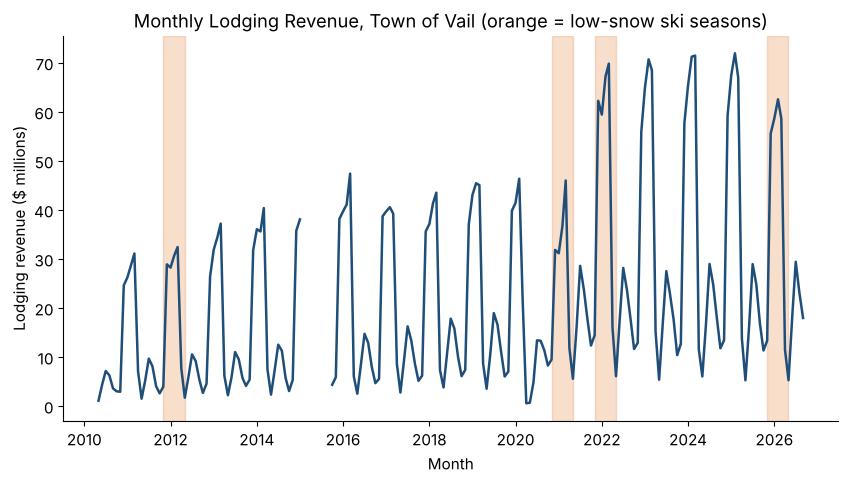

In [13]:
# Chart 1: revenue over time, low-snow seasons shaded
df["season"] = np.where(df["month_num"] >= 5, df["date"].dt.year, df["date"].dt.year - 1)
ss = df[df.ski_season == 1].groupby("season")["new_snow"].sum()
ss = ss[ss.index.isin(df.groupby("season").size()[lambda s: s >= 10].index)]
low = ss[ss <= ss.quantile(0.25)].index.tolist()
ts = df.set_index("date")["lodging_revenue"].reindex(pd.date_range(df.date.min(), df.date.max(), freq="MS")) / 1e6
fig, ax = plt.subplots()
ax.plot(ts.index, ts.values, color="#1f4e79", lw=1.8)
for s in low:
    ax.axvspan(pd.Timestamp(s, 11, 1), pd.Timestamp(s + 1, 4, 30), color="#d95f02", alpha=0.2)
ax.set(title="Monthly Lodging Revenue, Town of Vail (orange = low-snow ski seasons)", xlabel="Month", ylabel="Lodging revenue ($ millions)")
plt.show(); print("Low-snow seasons (bottom quartile of season new snow):", low)

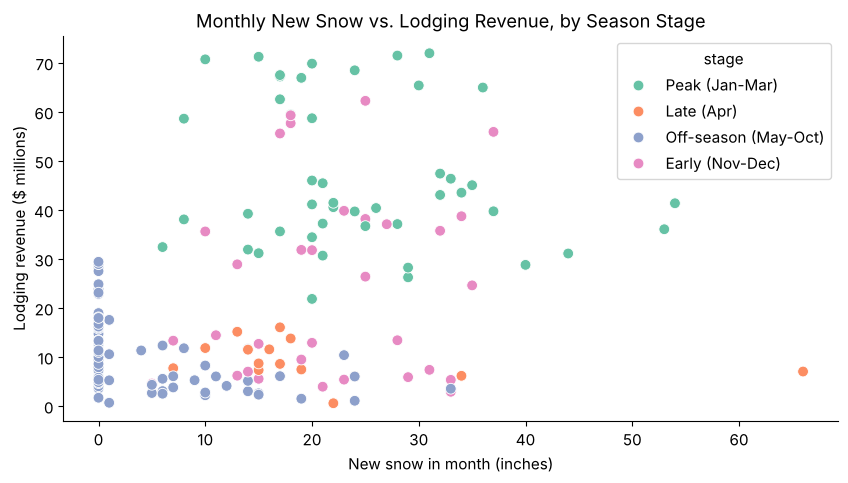

In [14]:
# Chart 2: snow vs revenue by season stage
stage = pd.cut(df["month_num"].replace({11: 11, 12: 12}), bins=[0, 3, 4, 10, 12], labels=["Peak (Jan-Mar)", "Late (Apr)", "Off-season (May-Oct)", "Early (Nov-Dec)"])
df["stage"] = stage
fig, ax = plt.subplots()
sns.scatterplot(data=df, x="new_snow", y=df.lodging_revenue / 1e6, hue="stage", palette="Set2", s=60, ax=ax)
ax.set(title="Monthly New Snow vs. Lodging Revenue, by Season Stage", xlabel="New snow in month (inches)", ylabel="Lodging revenue ($ millions)")
plt.show()

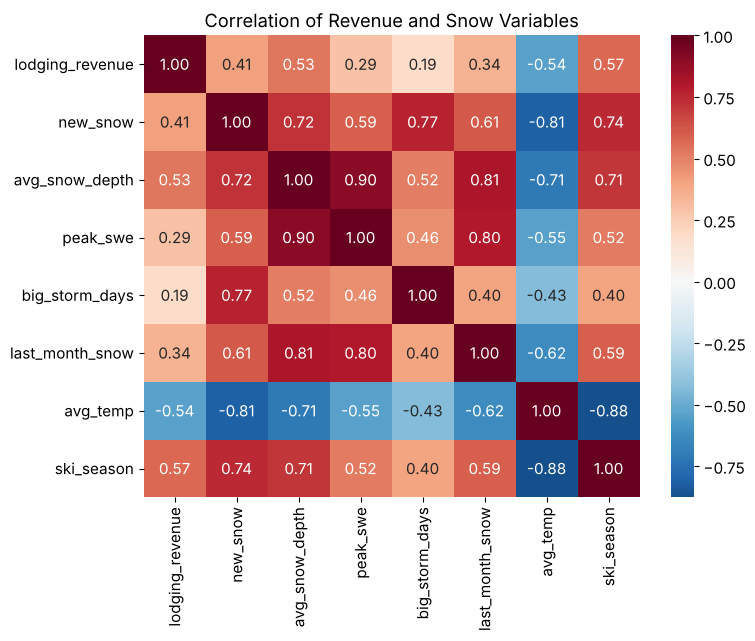

In [15]:
# Chart 3: correlation heatmap
cols = ["lodging_revenue"] + snow_cols + ["avg_temp", "ski_season"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation of Revenue and Snow Variables"); plt.show()

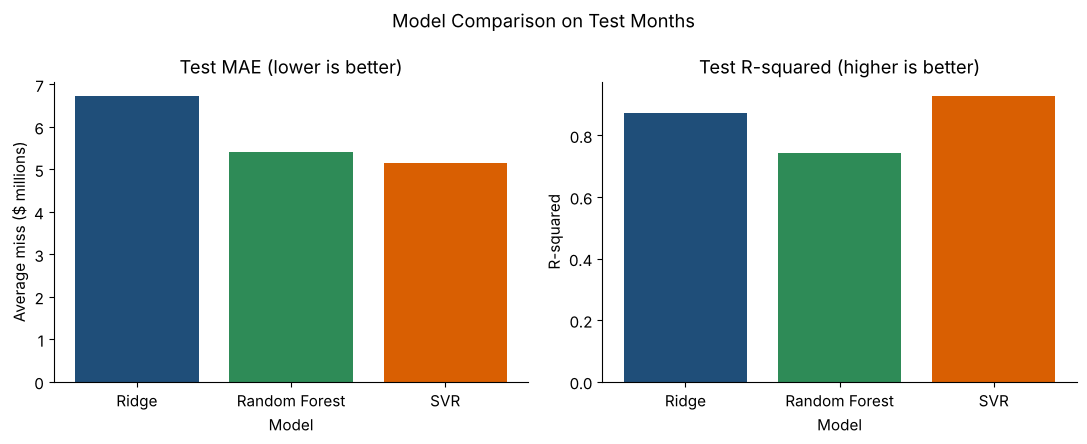

In [16]:
# Chart 4: model comparison (MAE and R2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cols_ = ["#1f4e79", "#2e8b57", "#d95f02"]
axes[0].bar(results.index, results["MAE ($)"] / 1e6, color=cols_); axes[0].set(title="Test MAE (lower is better)", ylabel="Average miss ($ millions)")
axes[1].bar(results.index, results["R2"], color=cols_); axes[1].set(title="Test R-squared (higher is better)", ylabel="R-squared")
for a in axes: a.set_xlabel("Model")
fig.suptitle("Model Comparison on Test Months"); plt.tight_layout(); plt.show()

avg_snow_depth     0.418
year_index         0.233
m_4                0.145
m_5                0.081
peak_swe           0.049
m_12               0.023
m_3                0.011
new_snow           0.009
m_7                0.008
last_month_snow    0.006
m_2                0.006
m_8                0.004


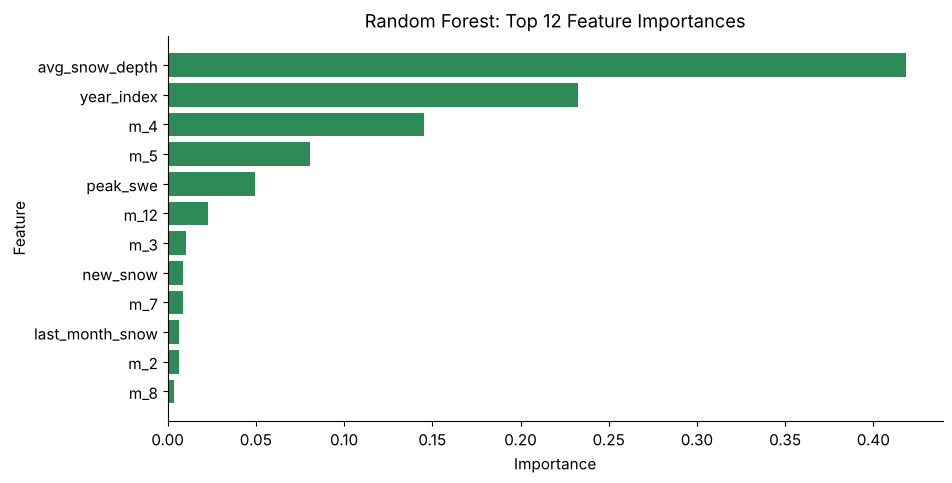

In [17]:
# Chart 5: Random Forest feature importance
rf_best = rf_gs.best_estimator_.named_steps["m"]
imp = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values().tail(12)
fig, ax = plt.subplots()
ax.barh(imp.index, imp.values, color="#2e8b57")
ax.set(title="Random Forest: Top 12 Feature Importances", xlabel="Importance", ylabel="Feature"); plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

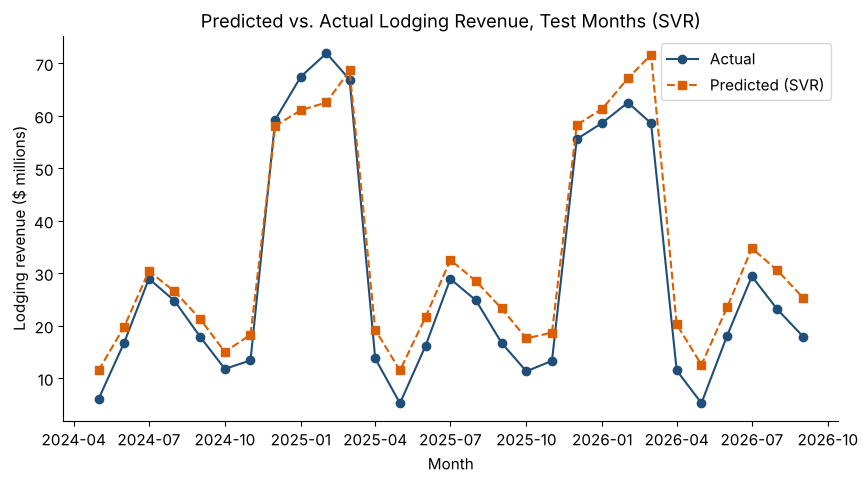

In [18]:
# Chart 6: predicted vs actual on test months, best model
dates = df.loc[test_mask, "date"]
fig, ax = plt.subplots()
ax.plot(dates, y_test / 1e6, "o-", color="#1f4e79", label="Actual")
ax.plot(dates, preds[best] / 1e6, "s--", color="#d95f02", label=f"Predicted ({best})")
ax.set(title=f"Predicted vs. Actual Lodging Revenue, Test Months ({best})", xlabel="Month", ylabel="Lodging revenue ($ millions)")
ax.legend(); plt.show()

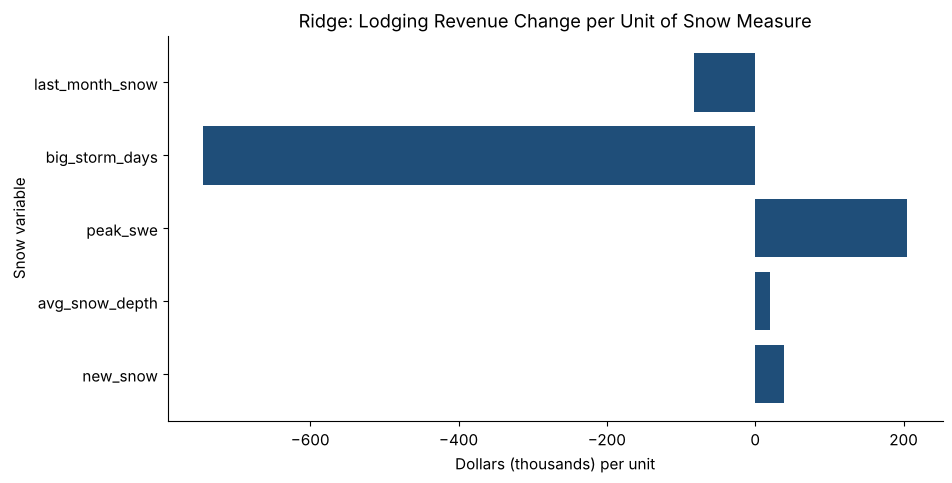

In [19]:
# Bonus chart: Ridge dollars per unit of snow
fig, ax = plt.subplots()
ax.barh(dollars.index, dollars.values / 1e3, color="#1f4e79")
ax.set(title="Ridge: Lodging Revenue Change per Unit of Snow Measure", xlabel="Dollars (thousands) per unit", ylabel="Snow variable"); plt.show()

## 12. Read-out for Vail
See the numbers above for the winning model, its average miss, and what the snow-removed check says about how much snow adds beyond the month and trend. The ranking between models can shift when the tuning grid or split changes (we saw SVR and Random Forest swap places), so read the winner as "close call" rather than a landslide. Two honest limits:
- **Few rows.** About 189 monthly rows, so we skipped neural networks (they would overfit) and treat the test score as approximate with only ~29 test months.
- **Epic Pass and pre-booked trips are not in this file.** To test whether they soften the snow link, add pass sales from the 10-K by season and check whether the snow effect shrinks as passes rise.